# Lab 2 — Linear Models for Classification: Wine Dataset

## How to work in this lab
Most of the code is provided. **Running the code is not the task; understanding what happens is the task.**

For the main investigations use the cycle:

**PREDICT → RUN & OBSERVE → EXPLAIN → EXPERIMENT**

Before an investigation, write your prediction on the Thinking Sheet **before** running the relevant code. Work in pairs.

The task is to perform a <u>classification</u> to decide from which cultivar the given wine has been grown.

We first import the dataset we are going to use and some packages that may be useful later.

In [1]:
# -- we need to import numpy for numerical computing
import numpy as np
#let's import the following for plotting
import matplotlib.pyplot as plt

# -- let's import the sklearn library
import sklearn

# -- let's print out the version of scikit-learn
print(sklearn.__version__)

# -- this imports the datasets module, which has useful datasets
from sklearn import datasets

# -- Load the dataset from scikit learn
wine = datasets.load_wine()

1.9.1


Let's check out the description of the dataset from the scikit learn documentation: https://scikit-learn.org/stable/api/sklearn.datasets.html.

(**Note**: we are considering the scikit-learn version that is installed in the labs Te and Ue, but there are more recent ones)

Now let's understand a little bit the data.

In [2]:
# -- let's print the dimension of the data matrix
print('Wine dataset shape:\n', wine.data.shape)

# -- let's print the features names
print('Feature names:\n', wine.feature_names)

# -- let's print the data matrix
print('Data:\n', wine.data)

# -- let's print the targets names
print('Target names:\n', wine.target_names)

# --let's print the target (labels)
print('Labels:\n', wine.target)

# -- let's print the description of the dataset
print('Dataset description:\n', wine.DESCR)

Wine dataset shape:
 (178, 13)
Feature names:
 ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Data:
 [[1.423e+01 1.710e+00 2.430e+00 ... 1.040e+00 3.920e+00 1.065e+03]
 [1.320e+01 1.780e+00 2.140e+00 ... 1.050e+00 3.400e+00 1.050e+03]
 [1.316e+01 2.360e+00 2.670e+00 ... 1.030e+00 3.170e+00 1.185e+03]
 ...
 [1.327e+01 4.280e+00 2.260e+00 ... 5.900e-01 1.560e+00 8.350e+02]
 [1.317e+01 2.590e+00 2.370e+00 ... 6.000e-01 1.620e+00 8.400e+02]
 [1.413e+01 4.100e+00 2.740e+00 ... 6.100e-01 1.600e+00 5.600e+02]]
Target names:
 ['class_0' 'class_1' 'class_2']
Labels:
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 

There are three different classes of cultivars (represented with labels 0, 1, and 2).

To simplify a bit the problem (and the presentation), we are going to consider a **binary classification** task. In particular, we are going to classify class "1" vs the other two classes (0 and 2), that we denote as "-1". 

Thus, we need to re-label the other classes (0 and 2) as "-1".

For convenience, let's save the instances (vectors of features) in matrix $\mathbf{X}$ and the targets into a vector $\mathbf{Y}$.

In [3]:
X: np.ndarray = wine.data
Y: np.ndarray = wine.target

# -- let's print out the matrix of instances and the vector of targets, 
# just to make sure that everything looks ok
print("Matrix of instances:")
print(X)

print("Vector of labels:")
print(Y)

Matrix of instances:
[[1.423e+01 1.710e+00 2.430e+00 ... 1.040e+00 3.920e+00 1.065e+03]
 [1.320e+01 1.780e+00 2.140e+00 ... 1.050e+00 3.400e+00 1.050e+03]
 [1.316e+01 2.360e+00 2.670e+00 ... 1.030e+00 3.170e+00 1.185e+03]
 ...
 [1.327e+01 4.280e+00 2.260e+00 ... 5.900e-01 1.560e+00 8.350e+02]
 [1.317e+01 2.590e+00 2.370e+00 ... 6.000e-01 1.620e+00 8.400e+02]
 [1.413e+01 4.100e+00 2.740e+00 ... 6.100e-01 1.600e+00 5.600e+02]]
Vector of labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


Let's relabel the labels for classes 0 and 2 as stated before.

In [4]:
# -- let's relabel classes 0 and 2 as -1

for i in range(len(Y)):
    if Y[i] != 1:
        Y[i] = -1
        
# -- let's print the new vector Y
print('Re-labeled classes:')
print(Y)

Re-labeled classes:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


## Investigation 1 — Train/test split

### PREDICT — do not run the next cells yet
Would taking the first half of the dataset for training and the second half for testing give a trustworthy estimate of generalization performance? Why or why not?


## Data Preprocessing and Split into Training and Testing ##

Before we actually learn the model, it is important that we perform two operations:
1. split the data into a training set and a test set;
2. normalize the features.

**Note**: some of these operations can be done in few lines with scikit-learn dedicated functions, but we do them "manually" to get a better understanding of what is going on.

*1) Train and Test split:*

We now want to split the data into train and test. Let's say we keep 50% of the data for training and 50% for testing. How do we split the data?

What about keeping the first 50% of the rows for training and the last 50% of rows for testing? Is it a good idea?

Let's see what happens if we split in this way.

In [5]:
# -- train-test split: 50% training, 50% test, keeping the first 50% for training
m: int = X.shape[0]
fraction_train: float = 0.5

m_train: int = int(m*fraction_train)
print('Number of samples in training set:', m_train)

m_test = m - m_train
print('Number of samples in test set:', m_test)

# -- explain what is slicing of arrays and how it works
# -- let's assign the train and test samples 

X_train: np.ndarray = X[:m_train,:]
Y_train: np.ndarray = Y[:m_train]

X_test: np.ndarray = X[m_train:,]
Y_test: np.ndarray = Y[m_train:]

print('Y training:', Y_train)

Number of samples in training set: 89
Number of samples in test set: 89
Y training: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]


Note that `Y_train` contains all the instances from class 0 (relabeled as -1) and no instance from class 2, while `Y_test` contains no instance from class 0 and all instances from class 2 (relabeled as -1). That is, the distribution of training data and test data is different!

**Solution**: randomly permute the rows, and split as suggested before only *after* the permutation is applied.

**Note**: since we use randomization in some parts, let's fix a random seed (so that the entire procedure is reproducible).

In [6]:
# In the code below:
# np.random.permutation(m) generates a random ordering of the indices from 0 to m-1.
# X[permutation] rearranges the rows of the data matrix.
# Y[permutation] rearranges the labels in exactly the same way.
# np.random.seed(IDnumber) makes the random permutation reproducible: using the same seed produces the same permutation.
 
# -- set the random seed to a number, e.g. to your ID number
IDnumber: int = 1
np.random.seed(IDnumber)

# -- let's generate a permutation among the number of rows
m: int = wine.data.shape[0]
permutation = np.random.permutation(m)

# -- visualize what permutation does
print('Permutation of indexes:\n', permutation)

X_perm = X[permutation]
Y_perm = Y[permutation]

#let's print Y_perm
print('Permutation of targets:\n', Y_perm)

Permutation of indexes:
 [161 117  19  69  53 138 112  14 160 107  11   4 108  42  84 113 152  35
 105  31  51 126 130  73  40 162  47  29  16 147  97 159 151   5 120  94
  91  81 114  48  54  59 165  39  56  44  78  33  18  58 127 172 148  12
  90  95  28 124 135  66 123  17 164  89 170  13 106  45  93  36 171 166
 168 175 118  75  21 173   2  70 163   6  85   0 136  77  65  55  99  88
 102  46  62  74  92 176 116 119 125 110  10  34  32 145  38  83 154 177
  27 100  23 103  67   9 150 104 122 132 153  87  98 111 167 158  64  15
  82  41 143 109  80  52  26  76  43  24   3 149  49 131 169  30 121 115
 155   8  60 128   1  57  22  61  63   7 174 141  86  96  68  50 142 157
 156 139 146 101  20  25 134  71 129 144  79 133 137  72 140  37]
Permutation of targets:
 [-1  1 -1  1 -1 -1  1 -1 -1  1 -1 -1  1 -1  1  1 -1 -1  1 -1 -1  1 -1  1
 -1 -1 -1 -1 -1 -1  1 -1 -1 -1  1  1  1  1  1 -1 -1  1 -1 -1 -1 -1  1 -1
 -1 -1  1 -1 -1 -1  1  1 -1  1 -1  1  1 -1 -1  1 -1 -1  1 -1  1 -1 -1 -1
 -1 -1  

Let's split the data and save into 2 new data matrices/vectors.

In [7]:
# -- train-test split: 50% training, 50% test
m: int = X_perm.shape[0]
fraction_train: float = 0.5

m_train: int = int(m*fraction_train)
print('Number of samples in training set:', m_train)

m_test = m - m_train
print('Number of samples in test set:', m_test)

Number of samples in training set: 89
Number of samples in test set: 89


In [8]:
# -- explain what is slicing of arrays and how it works
# -- let's assign the train and test samples 

X_train: np.ndarray = X_perm[:m_train,:]
Y_train: np.ndarray = Y_perm[:m_train]

X_test: np.ndarray = X_perm[m_train:,]
Y_test: np.ndarray = Y_perm[m_train:]

print('Y training:', Y_train)

Y training: [-1  1 -1  1 -1 -1  1 -1 -1  1 -1 -1  1 -1  1  1 -1 -1  1 -1 -1  1 -1  1
 -1 -1 -1 -1 -1 -1  1 -1 -1 -1  1  1  1  1  1 -1 -1  1 -1 -1 -1 -1  1 -1
 -1 -1  1 -1 -1 -1  1  1 -1  1 -1  1  1 -1 -1  1 -1 -1  1 -1  1 -1 -1 -1
 -1 -1  1  1 -1 -1 -1  1 -1 -1  1 -1 -1  1  1 -1  1]


### RUN & OBSERVE → EXPLAIN → EXPERIMENT
Inspect the class labels before and after permutation. Explain why the permutation matters.

**Experiment.** Compare the shuffled split with an unshuffled 50/50 split. Train the same classifier later in the notebook on both splits and compare the conclusions. Predict first.


## Investigation 2 — Feature scaling

*2) Features Normalization:*

We now center and scale the data to have zero mean and unit variance. This is an important step for the stability of the computation and for other reasons. We are going to use the standard scaler from scikit-learn: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html.

We are going to fit `StandardScaler` only using the training set. Then to normalize the test set we use the `StandardScaler` fit on the training set.

### PREDICT — do not run the checks yet
After fitting `StandardScaler` on the training set, what mean and standard deviation do you expect for each feature in the **scaled training set**? What about the **scaled test set**?

Will the test-set means be exactly 0 and standard deviations exactly 1? Explain your prediction.


In [9]:
# -- load the StandardScaler module
from sklearn.preprocessing import StandardScaler

# -- we first "learn" the scaler function using the training data
scaler: sklearn.preprocessing.StandardScaler = StandardScaler().fit(X_train)

# -- we then apply the scaling function to both training and test data, since we want to simulate what happens 
# -- when we have data for training and we have future data

# -- IMPORTANT: The test set must be scaled using training stats.
X_train_scaled: np.ndarray = scaler.transform(X_train)
X_test_scaled: np.ndarray =  scaler.transform(X_test)
    
# -- let's print the scaled version of X_train_scaled
print('X_train scaled:\n', X_train_scaled)

X_train scaled:
 [[ 0.75978906  0.90435899  0.63672355 ...  0.02998213 -1.19559091
  -0.25927744]
 [-0.77075732 -0.63309317 -0.71528317 ...  0.49486179  0.45548645
  -1.26662133]
 [ 0.69953133  0.75527272  0.71398107 ...  0.02998213  1.03481184
   0.23687701]
 ...
 [-0.83101506 -1.00580884  0.71398107 ...  1.09920535 -0.50040044
  -0.26529144]
 [ 0.60311896 -0.52127847  0.32769344 ...  0.12295806  0.55686839
   1.06380109]
 [-0.92742743  0.82049796 -0.63802564 ...  2.16842857  0.2672057
  -1.08319453]]


Alternatively, let's perform the same operation manually, without using the StandardScaler module

In [10]:
# -- let's compute the mean of each feature in the training data
X_means: np.ndarray = np.mean(X_train, axis=0)
print('Means of X_train:\n', X_means)
print('\n')

# -- let's compute the standard deviation of each feature in the training data
X_stds: np.ndarray = np.std(X_train, axis=0)
print('Standard deviations of X_train:\n', X_stds)
print('\n')

# -- let's scale the data by hand
X_train_scaled_byhand: np.ndarray = (X_train - X_means)/X_stds
X_test_scaled_byhand: np.ndarray = (X_test - X_means)/X_stds

# -- print the scaled version of X_train
print('X_train scaled by hand:\n', X_train_scaled_byhand)

Means of X_train:
 [1.30595506e+01 2.28943820e+00 2.37516854e+00 1.89651685e+01
 1.01651685e+02 2.31966292e+00 2.10921348e+00 3.58089888e-01
 1.68786517e+00 5.20955055e+00 9.53550562e-01 2.64550562e+00
 7.66224719e+02]


Standard deviations of X_train:
 [8.29769035e-01 1.07320413e+00 2.58874454e-01 3.24688619e+00
 1.62668071e+01 6.25440877e-01 9.97925066e-01 1.19670675e-01
 5.88945872e-01 2.26148547e+00 2.15109432e-01 6.90458261e-01
 3.32557734e+02]


X_train scaled by hand:
 [[ 0.75978906  0.90435899  0.63672355 ...  0.02998213 -1.19559091
  -0.25927744]
 [-0.77075732 -0.63309317 -0.71528317 ...  0.49486179  0.45548645
  -1.26662133]
 [ 0.69953133  0.75527272  0.71398107 ...  0.02998213  1.03481184
   0.23687701]
 ...
 [-0.83101506 -1.00580884  0.71398107 ...  1.09920535 -0.50040044
  -0.26529144]
 [ 0.60311896 -0.52127847  0.32769344 ...  0.12295806  0.55686839
   1.06380109]
 [-0.92742743  0.82049796 -0.63802564 ...  2.16842857  0.2672057
  -1.08319453]]


The values correspond to those seen above obtained with the scaler.

Let's check if the scaler did his job.

In [11]:
print('X_train mean:\n', np.mean(X_train_scaled, axis=0))
print('\n')
print('X_train std:\n', np.std(X_train_scaled, axis=0))

X_train mean:
 [-2.38510834e-15 -5.61348720e-17  2.06077352e-15  1.61481315e-15
 -3.36809232e-16  1.36345367e-15 -1.04909839e-15 -2.00838098e-16
 -6.83597997e-16  2.46993437e-16  7.23516128e-16 -8.80070049e-16
  3.74232480e-17]


X_train std:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
# -- the test data has been scaled with training mean and std
print('X_test mean:\n', np.mean(X_test_scaled, axis=0))
print('\n')
print('X_test std:\n', np.std(X_test_scaled, axis=0))

X_test mean:
 [-0.14204575  0.08742067 -0.06684078  0.32632821 -0.23484785 -0.07850642
 -0.16022009  0.06290672 -0.32928762 -0.13394795  0.03625017 -0.09796457
 -0.11625928]


X_test std:
 [0.94530282 1.07290981 1.10964721 1.02502292 0.71104031 0.99412865
 0.98977359 1.07187905 0.90780157 1.03968689 1.11571535 1.04789128
 0.88119444]


### EXPLAIN → EXPERIMENT
Explain why the scaler is fitted on `X_train` but then used to transform **both** training and test data.

**Experiment.** Deliberately try an incorrect preprocessing strategy (for example, fitting a separate scaler on the test set). The code may run perfectly: explain why the procedure is still conceptually wrong.


In [13]:
# -- we first "learn" the scaler function using the training data
# scaler: sklearn.preprocessing.StandardScaler = StandardScaler().fit(X_perm)

# -- we then apply the scaling function to both training and test data, since we want to simulate what happens 
# -- when we have data for training and we have future data

# -- IMPORTANT: The test set must be scaled using training stats.
# X_train_scaled: np.ndarray = scaler.transform(X_train)
# X_test_scaled: np.ndarray =  scaler.transform(X_test)
    
# -- let's print the scaled version of X_train_scaled
# print('X_train scaled:\n', X_train_scaled)

## Investigation 3 — Perceptron: learning a linear classifier

The Perceptron learns a linear decision rule. Before fitting it, recall what the dimension of its weight vector should be for this dataset.


## Learning a Model ##

We now need to decide which model/algorithm we are going to use for our classification task. There are several models available in scikit-learn: https://scikit-learn.org/stable/index.html.

### Optional exercise — Implementing the Perceptron
In the following exercise, you will implement the Perceptron algorithm from scratch. This is a useful way to understand how the algorithm learns, but it may require some additional time.

If you prefer, you can skip this exercise for now and continue directly from the section “From now on we use the Perceptron from scikit-learn to get used to the tool”, starting with "from sklearn.linear_model import Perceptron".

You can return to the implementation later, as an additional exercise to consolidate your understanding.

Whether you implement the algorithm yourself or use scikit-learn, make sure you understand how the Perceptron updates its parameters when it encounters a misclassified example.

### TO DO: IMPLEMENT THE PERCEPTRON

Even though there are many models directy implemented in scikit-learn (we will use them later), we start by implemeting our own perceptron as introduced in class.

The goal is not simply to write working Python code, but to understand **how the algorithm learns from misclassified examples**.

Recall that our binary classification problem uses labels $y_i\in\{-1,+1\}$.

The Perceptron learns a linear classifier of the form

$$
h_{w,b}(x)=\operatorname{sign}(w^\top x+b),
$$

where $w$ is the weight vector and $b$ is the bias.

### Step 1 — Understand the initialization

The function `my_perceptron` already initializes:

- `w`, a vector of zeros with one component for each feature;
- `b`, initially equal to zero;
- `rng`, a random number generator that can be used to select training examples.

**Before continuing, check:** How many components should `w` have for our Wine dataset? 

### Step 2 — Identify misclassified examples, select one of them and update w

For each training example $(x_i,y_i)$, compute:

$$
s_i=w^\top x_i+b.
$$

How do you identify missclassified examples, candidates for a Perceptron update?

**Your task:** Find the indices of all training examples satisfying this condition.

You may select one of these example randomly using the provided random number generator `rng`.

Then apply the Perceptron update rule. This will change s_i ...

### Step 3 — Decide when to stop

We use the following stopping conditions:

- **stop if there are no misclassified examples:** all training examples have strictly positive margins.
- **stop if the maximum number of iterations has been reached:** the algorithm has exhausted its update budget.

Notice that `max_iterations` counts the number of updates attempted by the main loop.


### Step 4 — Return the learned model

At the end of the algorithm, return `w` and `b` separately, as already specified in the function.

Do not change the function name, its parameters, or its return statement.


In [ ]:
#do not change the function name, input parameters, and default values
#the function allows to provide a seed as input, in case you use a random generator in the implementation
#your implementation should output the vector w and the bias b separately; w is np.array, while b is a (real) value

def my_perceptron(X, y, max_iterations=100, seed=None):
    # Accept any array-like input (list, list of lists, tuple, pandas object)
    # and work with a genuine ndarray from here on.
    # dtype=float additionally guarantees floating-point arithmetic whatever
    # the caller passed in, and makes a non-numeric column fail *here*, with a
    # clear message, instead of much later.
    X = np.asarray(X, dtype=float)
    # Labels are only ever compared and multiplied, so no cast is imposed:
    # an integer dtype for y is perfectly fine.
    y = np.asarray(y)

    # X must be 2-D -- one row per sample, one column per feature -- and y must
    # be 1-D with exactly one label per row of X. This catches the two usual
    # mistakes: passing a single sample as a flat vector, and passing y with
    # shape (m, 1) instead of (m,).
    if X.ndim != 2 or y.shape != (len(X),):
        raise ValueError("Incompatible X and y shapes.")
    # The algorithm encodes the class in the *sign* of the label: the whole
    # method rests on y_i (<w, x_i> + b) > 0 meaning "correctly classified".
    if not np.all(np.isin(y, [-1, 1])):
        raise ValueError("Labels must be -1 or +1.")

    #initialize w to be a np array of all zeros of the proper size
    w = np.zeros(X.shape[1])
    #initialize the bias b to be 0
    b = 0.0

    # Create a local random number generator for this call.
    # Passing an integer seed makes a run exactly reproducible;
    # seed=None (the default) draws fresh entropy from the OS, so every call
    # gives a different sequence. Note this is a *local* generator rather than
    # the global np.random.* functions: it cannot be perturbed by other cells
    # of the notebook drawing random numbers, so the result depends only on
    # the arguments of this function.
    rng = np.random.default_rng(seed)
    
    # TO DO: implement the main loop of the perceptron in the following
    # iterate a maximum of max_iterations times
    for t in range (max_iterations):
        missclassified = []
        
        # search the missclassified istance
        for j, (x_i, y_i) in enumerate(zip(X, y)):
            if (np.sign(np.dot(w, x_i) + b) != y_i):
                missclassified.append(j)
            j += 1
        
        # random choice of a missclassified instance
        if not missclassified:
            break
        else:
            i = rng.choice(missclassified)
        
            # updating weights and bias
            w += y[i] * X[i]
            b += y[i]
               
    #SUGGESTION: If you use randomness, use rng from above. For example,
    #if misclassified is an array of indexes of misclassified instances, and you want to pick an index i
    #uniformly at random from it, you can use:
    #i = rng.choice(misclassified)
    
    #do not change the output instruction
    return w, b

Now let's learn a linear model from the (scaled) data using the perceptron we implemented, and compute the training and test error.

# TO DO: complete the code by adding the code to compute the test error

In [34]:
#learn the model from scaled training data
w, b = my_perceptron(X_train_scaled, Y_train, max_iterations=1000, seed=7)
print("Weights:", w)
print("Bias:", b)

#compute the training error
num_errors_train = 0
for i in range(X_train_scaled.shape[0]):
    if (np.sign(np.dot(w,X_train_scaled[i,:])+b) != Y_train[i]):
        num_errors_train +=1
training_error = num_errors_train/X_train_scaled.shape[0]
print("Training error:", training_error)

#compute the test error
num_errors_test = 0

#TO DO: add the code that computes the test error and stores it in the variable test_error
test_error = float('nan')
for i in range(X_test_scaled.shape[0]):
    if (np.sign(np.dot(w,X_test_scaled[i,:])+b) != Y_test[i]):
        num_errors_test +=1
test_error = num_errors_test/X_test_scaled.shape[0]

print("Test error:", test_error)

Weights: [-5.34045997e+00 -1.64151940e+00 -2.76000344e+00  7.37785521e-01
 -2.76291591e-03 -2.12811680e+00 -6.83778345e-01  1.45624366e+00
  1.87384878e+00 -3.22414114e+00  2.88528346e+00  2.54398702e+00
 -3.36580909e+00]
Bias: -3.0
Training error: 0.0
Test error: 0.033707865168539325


### REMARK

In class, we introduced the perceptron algorithm without starting from an empirical risk minimization (ERM) formulation. We shall see that its update rule can be interpreted as a stochastic subgradient step for the **perceptron loss**, also called the **zero-margin hinge loss** (sometimes also referred to as  **linear loss**):
$$
\ell(w,b,(x,y))=\max\{0,-y(w^\top x+b)\}.
$$

The update may include an additional parameter, not introduced in class, called the **step size** or **learning rate**. When training examples are sampled uniformly from the dataset, this gives a version of Stochastic Gradient Descent (SGD), with subgradients replacing gradients where necessary. Our implementation samples only examples with nonpositive margin, thereby skipping zero updates.

**For the mathematically curious:** the loss is not differentiable at zero margin. The perceptron chooses a subgradient there that produces an update. Moreover, \(w=b=0\) already minimizes this loss, so the connection concerns the **update rule**, rather than ERM alone guaranteeing a separating classifier.

We shall discuss these details in class.

**TO DO** :  Check also the documentation of the  **Perceptron** algorithm in sci-kit learn: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html, and also other *linear models*: https://scikit-learn.org/stable/modules/linear_model.html.

From now on we use the Perceptron from ski-kit learn to get used to the tool.

In [16]:
from sklearn.linear_model import Perceptron

Let's use the Perceptron algorithm as implemented in scikit-learn. It proceeds in iterations.

The Perceptron has several parameters, some of which we will understand later on. An important one is $\texttt{tol}$, that represents how much the training error should improve in one iteration for the algorithm to continue. Note that this parameter is not present in the "simple" implementation of the orginal perceptron algorithm, but it provides an alternative termination condition. **In addition**, be aware that the sci-kit learn implementation also includes other features (such as **regularization**) that we shall discuss later on in class.

In [17]:
#let's learn a model using Perceptron

# The perceptron is a wrapper to the SGDClassifier fixing both loss and learning rate.
# loss is fixed to "perceptron" and "learning rate" is fixed to "constant".

# -- we first define the classifier, fixing the random state for reproducibility
perceptron = Perceptron(random_state = IDnumber, tol=1e-3)

# -- let's now learn the classifier (i.e., run the perceptron to fix the weights)
perceptron.fit(X_train_scaled, Y_train) # -- SEE DOCS

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",1
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


Let's print out the model we learned.

In [18]:
# -- interact asking what should be the dimension of coef (weights)

print("Coefficient of features in the model we learned:")
print(perceptron.coef_)

# -- interact asking bias dimension

print("Bias in the model we learned:")
print(perceptron.intercept_)

Coefficient of features in the model we learned:
[[-4.96848696 -1.74558664 -4.09074263  4.03186637 -1.72682244  0.3485182
   2.99148804 -0.34645642  2.28746151 -6.78434457  3.53914454  1.1485614
  -6.59931033]]
Bias in the model we learned:
[-6.]


How well does such a method perform?

We need to compute the training error of the hypothesis $h_S$ we learned from the training set $S$. There is no function in scikit-learn to compute the training error $L_S(h_S)$. However, there is a function to compute the **score**, that for the 0-1 loss corresponds to $1 - L_S(h_S)$.

### PREDICT → OBSERVE → EXPLAIN
Before comparing the two errors, predict which you expect to be smaller: training error or test error. Must that ordering hold in every finite experiment?

After running the cells, explain what each error measures and why test error is the relevant empirical proxy for generalization performance.


In [19]:
# -- let's compute the training error
training_error = 1.0 - perceptron.score(X_train_scaled, Y_train)

# -- let's print the training error
print("Training error: ", training_error)

Training error:  0.0


But we don't care about the training error... we are interested in the generalization error! How do we estimate it? Let's use the test data.

In [20]:
# -- let's compute the test error
test_error = 1.0 - perceptron.score(X_test_scaled, Y_test)

# -- let's print the test error
print("Test error: ", test_error)

Test error:  0.0449438202247191


## Investigation 4 — How much training data?

### PREDICT
Before running the experiment, sketch how you expect **training error** and **test error** to behave as the number of training examples increases. Do not aim for an exact curve: predict the qualitative trend and explain why.


## Impact of the amount of training data ##

We will now try to understand the impact of the amount of data we have for training.

To do this, we are going to train a model using a subset of the data with $i=10,11,12,\dots,n$ samples, where $n$ is the total number of training samples, and then compute the training error and the test error.

In [21]:
def compute_errors(X, Y, n_samples):

    # -- total number of samples, useful for later on
    m_total = X.shape[0]
    
    # -- two lists where to save the training error and the test error, useful for plotting
    train_errors = list()
    test_errors = list()
    
    # -- let's define the learner we use in this part
    perceptron = Perceptron(random_state = IDnumber, tol=1e-3)
    
    for idx_iter in range(10, n_samples + 1):
        # -- we now repeat all the previous steps
        # -- split into training and test
        m_training = idx_iter
        
        X_train = X[:m_training,:]
        Y_train = Y[:m_training]
    
        X_test = X[m_training:,]
        Y_test = Y[m_training:]
        
        # -- scale the data according to the training test, for both training and testing
        scaler = StandardScaler().fit(X_train)
        X_train_scaled = scaler.transform(X_train)
        X_test_scaled =  scaler.transform(X_test)
        
        # -- let's now learn the classifier (i.e., run the perceptron to fix the weights)
        perceptron.fit(X_train_scaled, Y_train)
        
        train_errors.append(1.0 - perceptron.score(X_train_scaled, Y_train))
        test_errors.append(1.0 - perceptron.score(X_test_scaled, Y_test))

    return train_errors, test_errors


In [22]:
def plot_errors(X, Y, n_samples):
    train_errors, test_errors = compute_errors(X, Y, n_samples)
    
    sample_range = list(range(10, n_samples + 1))
    
    plt.plot(sample_range, train_errors, 'x:', markevery= n_samples // 10)
    plt.plot(sample_range, test_errors, 'o--', markevery= n_samples // 10)
    
    plt.xlabel("Number of samples")
    plt.ylabel("Error")
    plt.legend(["Training error","Test error"])
    plt.show()

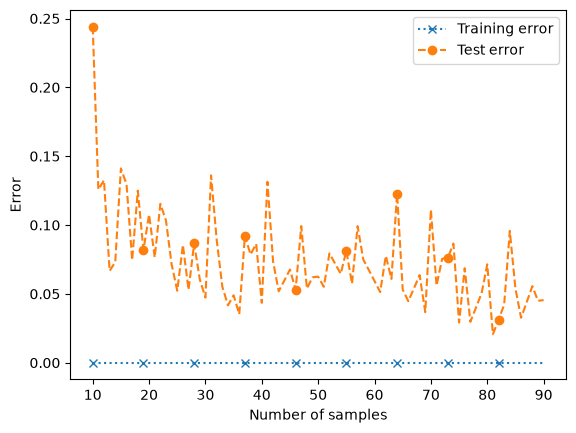

In [23]:
n_samples: int = 90
plot_errors(X_perm, Y_perm, n_samples)

### RUN & OBSERVE → EXPLAIN → EXPERIMENT
Compare the observed curves with your sketch. Why are the curves irregular rather than perfectly smooth?

**Experiment.** Repeat with a different data permutation/random seed. Which aspects of the result are stable, and which are sample-dependent?


## Investigation 5 — Same data, different learned model

### PREDICT
If two Perceptrons see the same scaled training data but use different random states, must they learn the same parameters? Must they make the same predictions? Commit to your answers first.


## Impact of random_state of the perceptron 

Let's learn a model with a different random seed for the Perceptron and see how different the model is from the previous one.

In [24]:
#let's learn a new model using Perceptron

# -- we first define the classifier, fixing the random state for reproducibility
old_perceptron = Perceptron(random_state = 1*IDnumber, tol=1e-3)
new_perceptron = Perceptron(random_state = 2*IDnumber, tol=1e-3)

# --let's now learn the classifier (i.e., run the perceptron to fix the weights)
old_perceptron.fit(X_train_scaled, Y_train)
new_perceptron.fit(X_train_scaled, Y_train)


# -- let's print the training error
print("Training error of old perceptron: ", 1.0 - old_perceptron.score(X_train_scaled, Y_train))
print("Training error of new perceptron: ", 1.0 - new_perceptron.score(X_train_scaled, Y_train))

# -- let's print the test error
print("Test error of old perceptron: ", 1.0 - old_perceptron.score(X_test_scaled, Y_test))
print("Test error of new perceptron: ", 1.0 - new_perceptron.score(X_test_scaled, Y_test))

Training error of old perceptron:  0.0
Training error of new perceptron:  0.0
Test error of old perceptron:  0.0449438202247191
Test error of new perceptron:  0.0674157303370787


In [ ]:
def plot_model_parameters(old_perceptron, new_perceptron):
    
    # -- let's plot the parameters of the two different models
    
    fig, axs = plt.subplots(1, 1)
    
    axs.bar(x = range(0, 42, 3), height = np.append(old_perceptron.coef_[0], old_perceptron.intercept_), 
            color='C0', edgecolor='k', linewidth=.5);
    axs.bar(x = range(1, 42, 3), height = np.append(new_perceptron.coef_[0], new_perceptron.intercept_), 
            color='C1', edgecolor='k',  linewidth=.5);
    bars = {'OLD Perceptron parameters' : 'C0', 'NEW Perceptron parameters' : 'C1'}
    labels = bars.keys()
    handles = [plt.Rectangle((0,0),1,1, color=bars[label], ec='k') for label in labels]
    axs.axhline(y = 0, color='k', linewidth=0.25);
    
    axs.legend(handles, labels, loc='best', frameon=False)
    
    # -- axis labels
    axs.set_xlabel('Parameter (weights and bias)', fontsize=14)
    axs.set_ylabel('Value',  fontsize=14)
    # -- ticks
    axs.set_xticks([0.5 + 3*i for i in range(14)]);
    xlabels = [f'$w_{ {i+1} }$' for i in range(13)];
    xlabels.append('$b$')
    axs.set_xticklabels(xlabels);
    axs.tick_params(axis='y', labelsize=14)
    axs.tick_params(axis='x', labelsize=11)


In [ ]:
plot_model_parameters(old_perceptron, new_perceptron)

Now let's print some instances for which the two models make different predictions.

In [ ]:
# -- the following is to show that, besides the different parameters, the models will also perform 
#    differently on classification task.
# -- we can explain the following (recall: data is linearly separable)
# -- try both for X_train_scaled and X_test_scaled

w_1 = old_perceptron.coef_
b_1 = old_perceptron.intercept_
w_2 = new_perceptron.coef_
b_2 = new_perceptron.intercept_

for i in range(X_test_scaled.shape[0]):
    sample = X_test_scaled[i, :]
    pred_1 = np.dot(w_1, sample) + b_1
    pred_2 = np.dot(w_2, sample) + b_2
    if pred_1[0] * pred_2[0] < 0:
        print('# Sample index', i)
        print('--> Prediction of first model = ', int(np.sign(pred_1)[0]))
        print('--> Predicion of second model =  ', int(np.sign(pred_2)[0]))
        # break

# -- you can see that for training set there are no such misclassified samples (indeed, they both have training error = 0.0)

### EXPLAIN
Use the parameters, training/test errors, and disagreements in predictions as evidence. How can two different linear separators both be plausible solutions?


## Investigation 6 — Does scaling matter for the Perceptron?

### PREDICT
What do you expect to change if the same Perceptron is trained on the original, unscaled features? Consider both performance and learned coefficients.


## Impact of normalization

Let's try to understand what the impact of scaling data is. Let's learn a model without normalizing the data.

In [ ]:
# -- let's learn a new model using Perceptron

# -- we first define the classifier, fixing the random state for reproducibility
perceptron_not_scaled = Perceptron(random_state = IDnumber, tol=1e-3)
# -- let's now learn the classifier (i.e., run the perceptron to fix the weights)
perceptron_not_scaled.fit(X_train, Y_train)

# -- let's print the training error
print(f'Training error (not-scaled model): {1.0 - perceptron_not_scaled.score(X_train, Y_train)}')
print(f'Training error (scaled model):     {1.0 - old_perceptron.score(X_train_scaled, Y_train)}')

print('---')

# -- let's print the test error
print(f'Test error (not-scaled model): {1.0 - perceptron_not_scaled.score(X_test, Y_test)}')
print(f'Test error (scaled model):     {1.0 - old_perceptron.score(X_test_scaled, Y_test)}')

print('---')

# -- let's print out the features of the model we just learned
print("NEW MODEL - Coefficients of features:")
print(perceptron_not_scaled.coef_)
print("PREVIOUS MODEL - Coefficients of features:")
print(old_perceptron.coef_)

print("NEW MODEL - Bias:", perceptron_not_scaled.intercept_)
print("PREVIOUS MODEL - Bias:", old_perceptron.intercept_)

In [ ]:
plot_model_parameters(old_perceptron, perceptron_not_scaled)

# Impact of normalization

## DOES SCALING ALWAYS HELP?

### Warning:
scaling just changes the geometry of the optimization problem. One can easily give examples where scaling DOES NOT help.

In [ ]:
def perceptron_history(X, y, max_epochs=100):
    # minimal perceptron (no bias), only to record the updates on the toy example
    w = np.zeros(X.shape[1])
    history = []
    for _ in range(max_epochs):
        mistakes = 0
        for i in range(len(X)):
            if y[i] * (X[i] @ w) <= 0:
                w = w + y[i] * X[i]
                history.append((i, w))
                mistakes += 1
        if mistakes == 0:
            break
    return w, history

In [ ]:
epsilon = 0.1
X = np.array([[1, epsilon], [1, -epsilon],
              [-1, epsilon], [-1, -epsilon]])
y = np.array([1, 1, -1, -1])

# Both features have zero mean; divide by population standard deviations.
X_scaled = X / X.std(axis=0)


fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

for ax, data, title in zip(
    axes, [X, X_scaled], ["Original data", "Standardized data"]
):
    w, history = perceptron_history(data, y)

    #print(history)   
    
    
    B_squared = np.max(np.sum(data**2, axis=1))
    # For these symmetric datasets, the maximum unit-weight margin is 1.
    mistake_bound = B_squared

    print(f"{title}: {len(history)} updates, final w = {w}")

    #for entry in history:
    #    print(f"  Update on sample {entry['index']}: w = {entry['w']}")
    for i, w_i in history:
        print(f"  Update on sample {i}: w = {w_i}")
 
    print(f"  M²B² = {mistake_bound:.2f}\n")

    for label, color in [(1, "tab:blue"), (-1, "tab:orange")]:
        points = data[y == label]
        ax.scatter(points[:, 0], points[:, 1], c=color,
                   label=f"Class {label:+d}", s=80)

    # Display the boundary immediately after the FIRST update.

    w_first = history[0][1]
    
    t = np.linspace(-1.3, 1.3, 200)
    ax.plot(-w_first[1] / w_first[0] * t, t, "k--",
            label="Boundary after first update")

    ax.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4),
           xlabel="Feature 1", ylabel="Feature 2",
           title=f"{title}: {len(history)} updates")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.show()

### EXPLAIN → EXPERIMENT
Explain why feature scale can affect an iterative learning algorithm even though the classification problem itself has not changed.

**Experiment.** Artificially multiply one feature by a large constant, retrain, and compare. Predict before running.


## Investigation 7 — Logistic Regression vs Perceptron

We now train a second **linear classifier** on exactly the same scaled data: Logistic Regression.

### PREDICT
Both methods produce linear decision boundaries. Should they necessarily learn the same coefficients, make the same predictions, or obtain the same test error? Why?

Also: what extra output can Logistic Regression naturally provide that the Perceptron does not interpret as a probability?


In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(random_state=IDnumber, max_iter=2000)
logreg.fit(X_train_scaled, Y_train)

print("Perceptron training error:", 1.0 - perceptron.score(X_train_scaled, Y_train))
print("Perceptron test error:    ", 1.0 - perceptron.score(X_test_scaled, Y_test))
print("LogReg training error:   ", 1.0 - logreg.score(X_train_scaled, Y_train))
print("LogReg test error:       ", 1.0 - logreg.score(X_test_scaled, Y_test))

print("\nPerceptron coefficients:")
print(perceptron.coef_)
print("\nLogistic Regression coefficients:")
print(logreg.coef_)

pred_p = perceptron.predict(X_test_scaled)
pred_l = logreg.predict(X_test_scaled)
disagree = np.flatnonzero(pred_p != pred_l)
print("\nNumber of test samples on which predictions disagree:", len(disagree))
print("Indices of disagreements:", disagree)

proba = logreg.predict_proba(X_test_scaled)
print("\nFirst five Logistic Regression class probabilities:")
print(proba[:5])


### RUN & OBSERVE → EXPLAIN
Compare coefficients, predictions, and errors. Explain why “both are linear classifiers” does **not** imply “they learn the same model.”

Look at the Logistic Regression probabilities. What does a probability close to 0.5 suggest compared with one close to 0 or 1?


### EXPERIMENT
Choose **one** controlled change: training-set size, random split, or regularization strength `C` in Logistic Regression. Predict how the comparison between the two classifiers might change, then test it.

Do not search for the “best” model. Your goal is to explain the effect of the change.


# End-of-lab retrieval — close the notebook
Without looking back, discuss with your partner:

1. Why do we need a test set?
2. Why must preprocessing be learned from training data only?
3. What did increasing the amount of training data change?
4. How can Perceptron and Logistic Regression both be linear classifiers but learn different models?


